In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160)
OUT = ROOT / "outputs"
def show(name): display(Image(filename=str(OUT / "figures" / f"{name}.png")))


# 04 Baseline and GARCH models (saved walk-forward output)

In [2]:
f = pd.read_csv(OUT / "forecasts" / "volatility_forecasts_main.csv", parse_dates=["forecast_date"])
p = f.pivot(index="forecast_date", columns="model_name", values="predicted_volatility")
p["actual"] = f[f.model_name == "garch"].set_index("forecast_date")["actual_realized_volatility"]
from src.models.evaluate_forecasts import summarize
ev = p.dropna()
summarize(ev["actual"], ev[["historical_vol", "garch"]]).round(4)

,n,RMSE,MAE,QLIKE,bias
historical_vol,8405.0,0.0775,0.0504,0.4631,0.0070
garch,8405.0,0.0713,0.0480,0.3902,0.0116


fits: 401 | convergence flags: {0: 401} | fallbacks: 0


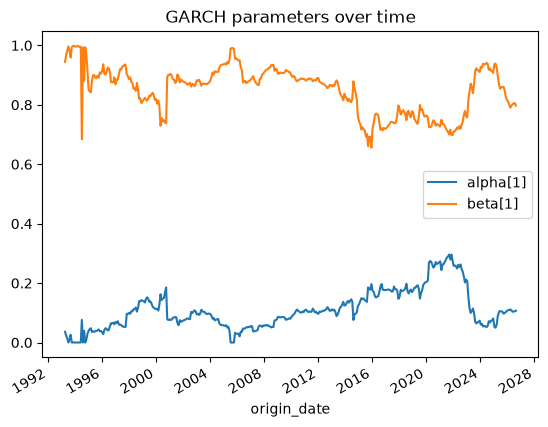

In [3]:
g = pd.read_csv(OUT / "forecasts" / "garch_fit_log_main.csv", parse_dates=["origin_date"])
print("fits:", len(g), "| convergence flags:", g.convergence_flag.value_counts().to_dict(), "| fallbacks:", int(g.used_previous_params.sum()))
g.set_index("origin_date")[["alpha[1]", "beta[1]"]].plot(title="GARCH parameters over time")
plt.show()

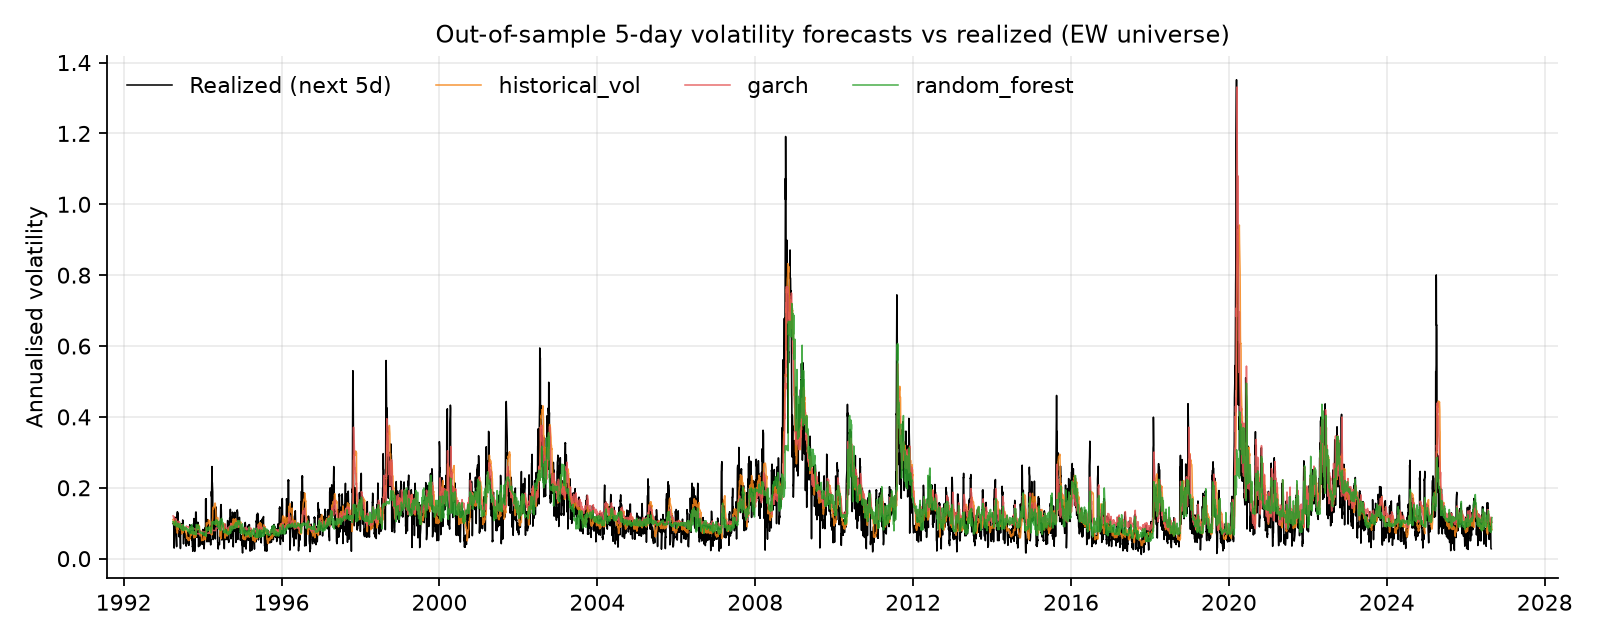

In [4]:
show('fig_actual_vs_predicted_vol')